In [28]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
# sys.path.append(r'G:\My Drive\butools2\Python')
sys.path.append('../../code')
sys.path.append('../../code/pycharm')
sys.path.append('../../code/butools2/Python')
from sample_PH import *
from utils import *
import time
from single_station_PH import *
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.stats import norm 
import statistics 
from butools.ph import *
from butools.fitting import *

<div dir="rtl">

## אנחנו רוצים לסמלץ מערכת תורים שמדמה מערכת אמיתית. בשביל לסמלץ את המערכת אנחנ צריכים לדעת מה ההתפלגות של זמנים בין הגעות וזמני שירות. אבל מאיפה לנו??

## Call center data: service times

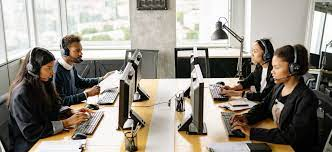

In [5]:
Image('../../Images/callcenter.jpg', width=420)

In [18]:
data

,duration
0,699
1,10
2,132
3,164
4,159
...,...
94529,1
94530,77
94531,2056
94532,16


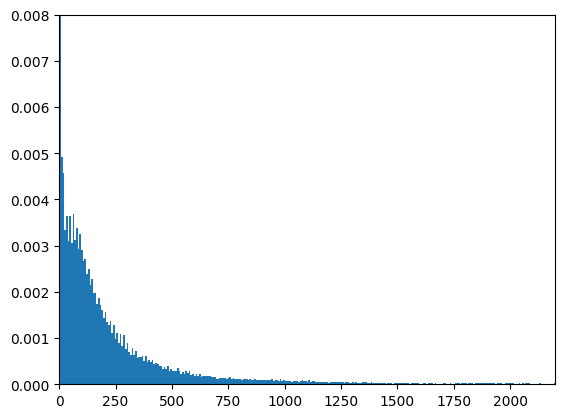

In [19]:
data = pd.read_csv("../../data/call_center.csv")

plt.figure()
plt.hist(data['duration'], bins = 1250, density = True)
plt.ylim(0,0.008)
plt.xlim(0,2200)
plt.show()

<div dir="rtl">

### לכל ארגון יש נתוני עבר, אנחנ יכולים לחלץ את אותם זמנים מהdata של הארגון די בקלות. אבל איך נתאים לו התפלגות?

    
#### יש כל מיני אפשרויות:
    
<div dir="rtl">

* נניח שזה מגיע מהתפלגות מיוחדת ואז נשתמש בסטטיטיקה קלאסית כדי למצוא את אותם פרמטרים

<div dir="rtl">

* פשוט ניקח את כל הערכים שהיו בעבר ונדגום מהרשימה הזאת: קוראים לזה ההתפלגות האמפירית

<div dir="rtl">

* שיטה שנקראת EM העוזרת לנו למצוא את הפרמטרים של התפלגות PH

<div dir="rtl">

### נעשה דוגמה וננסה את כל השיטות:

<div dir="rtl">

## לפנינו ההתפלגות הבאה:

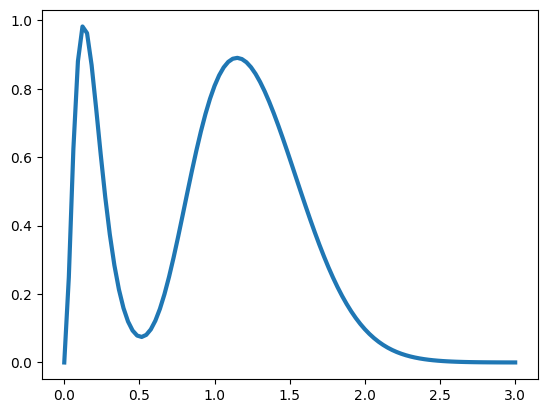

In [29]:
a,S, services = pkl.load(open('../../pkls/fitting_example.pkl', 'rb'))

x_vals  = np.linspace(0,3,100)
y_vals = compute_pdf_within_range(x_vals, a, S)

plt.figure()
plt.plot(x_vals, y_vals, lw = 3)
plt.show()

<div dir="rtl">

## אם נדגום ונעשה הסטורגרמה נקבל: 

In [30]:
services.shape

(50000,)

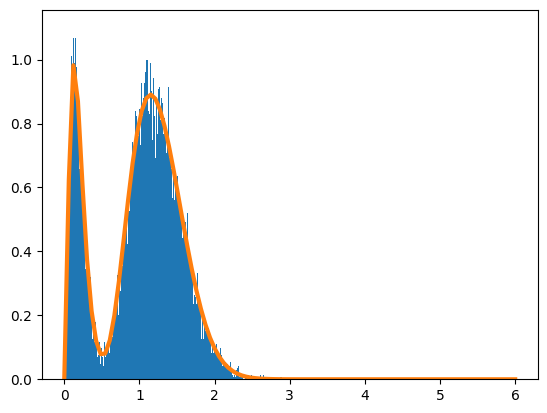

In [31]:
x_vals  = np.linspace(0,6,100)
y_vals = compute_pdf_within_range(x_vals, a, S)

plt.figure()
plt.hist(services, density = True, bins = 1000)
plt.plot(x_vals, y_vals, lw = 3)
plt.show()

<div dir="rtl">
    
## יש לנו 50000 דגימות. 
    
###    :נניח כי ההתפלגות היא מעריכית: ונחפש את הפרמטרים הכי מתאימים
    
### במקרה של מעריכי צריך למצוא רק את $\mu$:
    
$$ X \sim Exp(\mu) $$

In [32]:
def exp_density(mu, x_vals):
    return mu*np.exp(-x_vals*mu )
  
# Plot between -10 and 10 with .001 steps. 
x_vals = np.linspace(0,5,100) 
  
# Calculating mean and standard deviation 
mean = statistics.mean(services) 
mean

1.0007336260690247

<div dir="rtl">

## אם התוחלת שווה ל:

## $$ E[X] = \frac{1}{\lambda} $$

### אזי:

## $$  \hat{\lambda} = \frac{1}{\bar{x}} $$

### זה יהיה גם אומד נראות מקסימאלי - אם זוכר לכם בקורס סטטיסטיקה

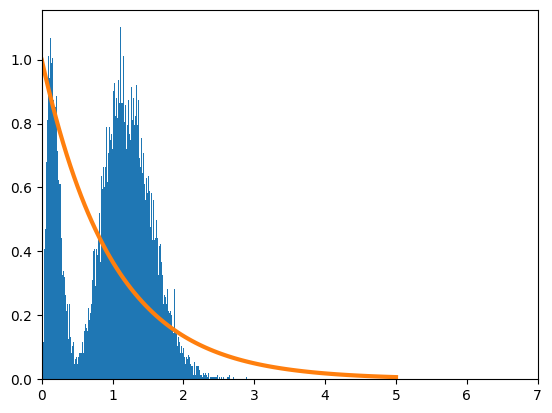

In [23]:

plt.figure()
plt.hist(services, density = True, bins = 1000)
plt.xlim(0,7)
plt.plot(x_vals, exp_density(1/mean, x_vals), lw =3) 
plt.show() 

<div dir="rtl">

### לא נראה מאד מתאים
    
### דגימה מהאמפירית - פשוט בוחרים אקראית ערך אחר כל פעם. הבעיה היא שהיא מוטה בצורה כבדה לנתונים שראינו ויכולה לגרום להטיה חמורה

<div dir="rtl">

## EM algorithm: Expectation Maximization
    

<div dir="rtl">


## EM הוא אלגוריתם שמוצא לנו את הPH הכי טוב שהוא יכול.
    
## צריך להזין לאלגוריתם את גודל הPH. גודל הPH מעלה את הדיוק של ההתאמה אך גם גוזל זמן ריצה.

Runtime for 5 is 2.665929079055786


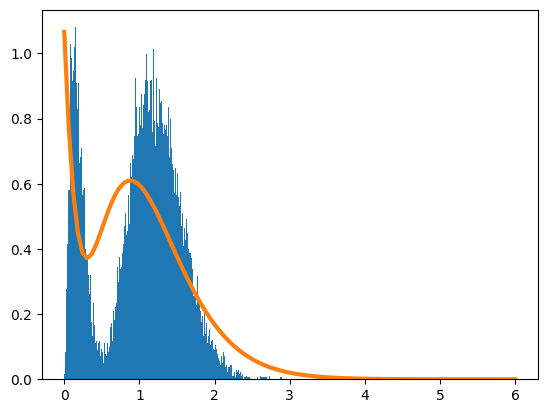

Runtime for 10 is 35.47034025192261


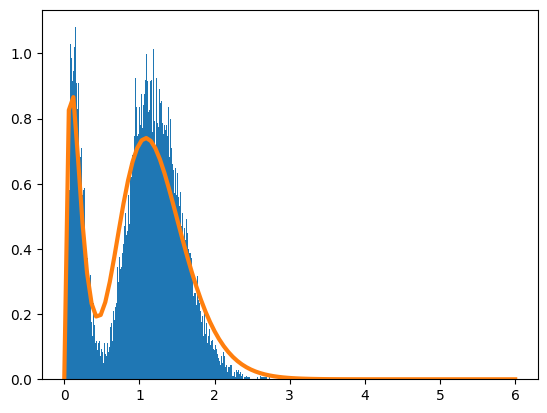

Runtime for 15 is 221.27649521827698


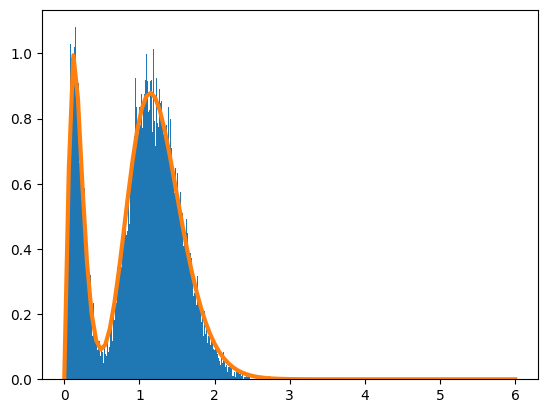

Runtime for 20 is 1199.661018371582


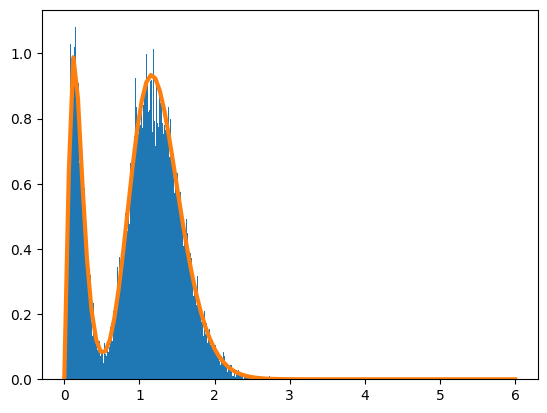

In [24]:
for size in [5,10,15, 20]:
    begin = time.time()
    res_EM = PHFromTrace(services, size)


    x_vals  = np.linspace(0,6,100)
    a_EM = np.array(res_EM[0]).flatten()
    S_EM = np.array(res_EM[1])
    
    end = time.time()
    print('Runtime for {} is {}' .format(size, end-begin))
    
    y_vals = compute_pdf_within_range(x_vals, a_EM, S_EM)

    plt.figure()
    plt.hist(services, density = True, bins = 800)
    plt.plot(x_vals, y_vals, lw = 3)
    plt.show()

<div dir="rtl">

## כאשר הגודל של הPH היה 5 ההתאמה לא הייתה טובה. ניתן גם לראות את השיפור כאשר גודל PH עלה.

<div dir="rtl">

    
## בואו נראה כיצד זמן ריצה עולה בגודל PH:

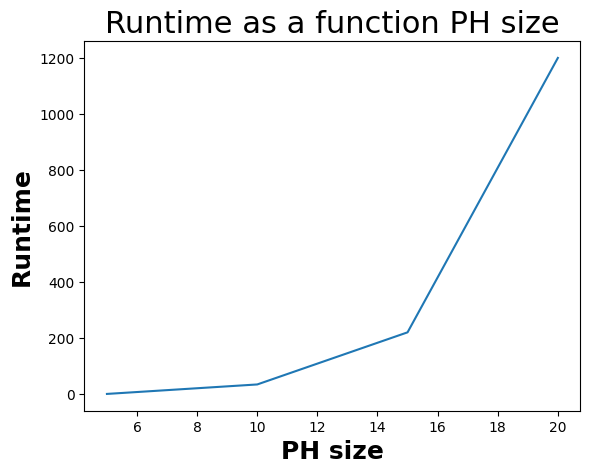

In [27]:
run_time = [1.713, 35.470, 221.276495218,  1199.661018371582]
  
plt.figure()
plt.title('Runtime as a function PH size', fontsize = 22)
plt.plot([5,10,15, 20], run_time)
plt.xlabel('PH size', fontsize = 18, fontweight = 'bold')
plt.ylabel('Runtime', fontsize = 18, fontweight = 'bold')
plt.show()

<div dir="rtl">

### ניתן לראות כי גודל הPH מצד אחד מאד עוזר לדיוק אך מאידך עולה לנו ביוקר בזמני ריצה.
    
### הגדלת גודל הPH בקצת מגדיל את הזמן בצורה משמעותית - במקרה הזה יש גדילה מעריכית

<div dir="rtl">


## מה שמעניין זה לדעת כיצד השגיאה משפיעה הסימולציה של התור
    
## נניח כי הנתונים הנ"ל הם נתונים של זמני שירות. 
    
## נניח כי ישנו תור יחיד במערכת שירות וכי תהליך ההגעה ידוע
    
## נסמלץ את התור ונקבל התפלגות של זמני שהייה והתפלגות מספר צרכנים במערכת
    
## נסמלץ תחילה עם ההתפלגות האמיתית ולאחר מכן נסמלץ בעזרת ההתפלגויות שאנחנו מצאנו
    
## לבסוף נשווה בין שתי הסימולציות 

In [2]:
a1,S1, services = pkl.load(open('../../pkls/fitting_example.pkl', 'rb'))

In [43]:
lamda = 0.9
services.shape

(50000,)

<div dir="rtl">

## סימולציה של ההתפלגות האמיתית

In [44]:
sim_time = 100000
queue_single_station_true = Queue_single_station(lamda, services, sim_time)
queue_single_station_true.run()
steady_true = queue_single_station_true.get_steady_single_station()

<div dir="rtl">

## סימלוציה של PH מותאם בגודל 20:

In [46]:
services_20 = SamplesFromPH(res_EM[0], res_EM[1], 50000)
queue_single_station_20 = Queue_single_station( lamda, services_20, sim_time)
queue_single_station_20.run()
steady_20 = queue_single_station_20.get_steady_single_station()
steady_20[:10]

array([0.09803597, 0.11808999, 0.11631437, 0.10091276, 0.08805973,
       0.07435505, 0.06219245, 0.0537565 , 0.04592797, 0.0394803 ])

<div dir="rtl">

## סימולציה של PH מותאם בגודל 5:

In [47]:
services_5 = SamplesFromPH(res_EM_5[0], res_EM_5[1], 50000)
queue_single_station_5 = Queue_single_station( lamda, services_5, sim_time)
queue_single_station_5.run()
steady_5 = queue_single_station_5.get_steady_single_station()
steady_5[:10]

array([0.09915435, 0.1110864 , 0.10388459, 0.09155183, 0.07869128,
       0.06901753, 0.06065576, 0.05113574, 0.04548855, 0.03990208])

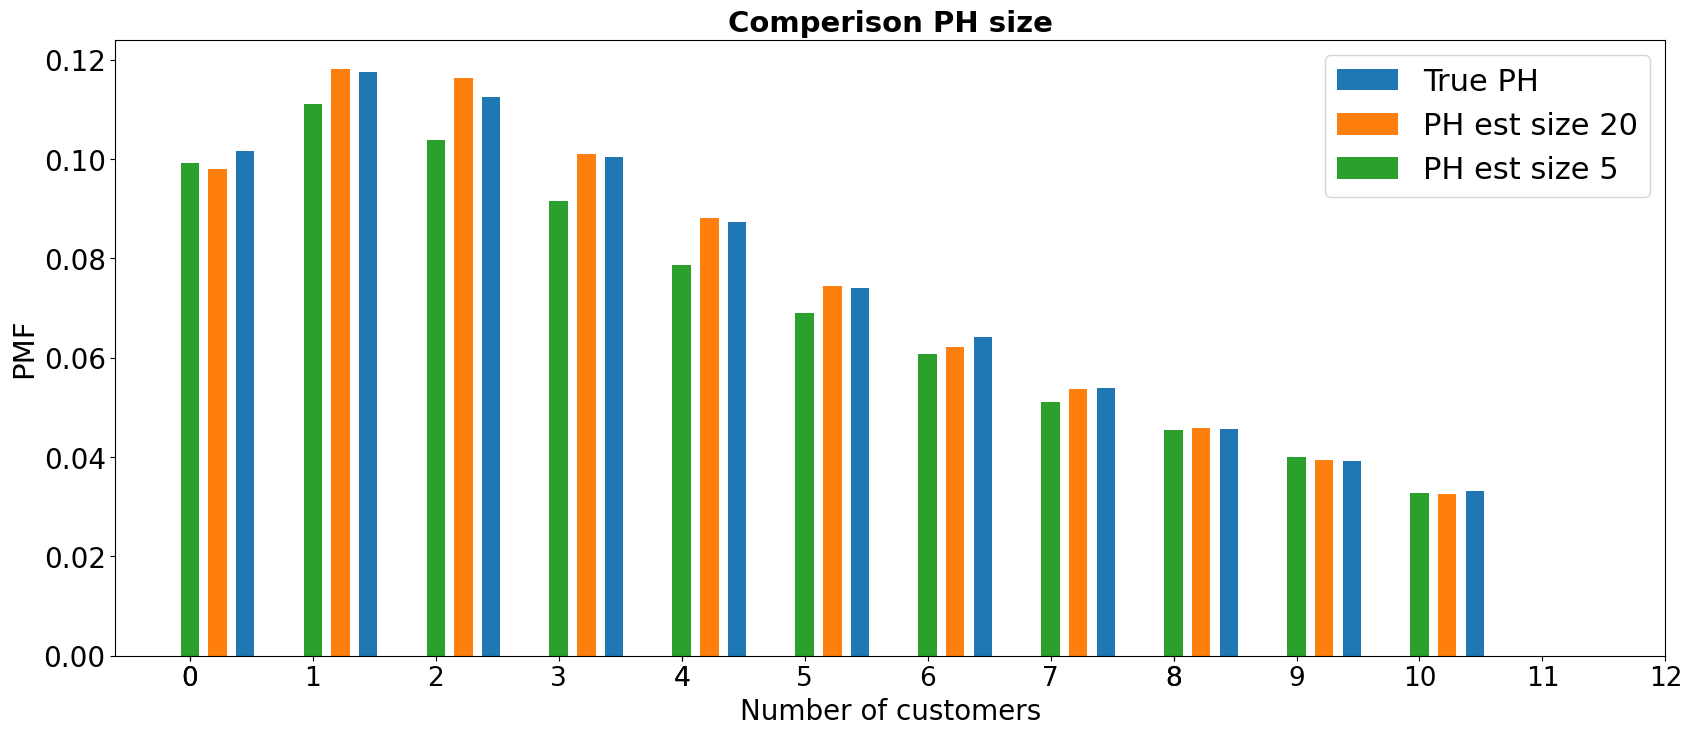

In [48]:
fig, (ax1) = plt.subplots(1, 1, figsize=(20, 8))
width = 0.15
max_probs = 11
rects1 = ax1.bar(3*width+np.arange(max_probs), steady_true[:11], width, label='True PH')
rects2 = ax1.bar(1.5*width+np.arange(max_probs) , steady_20[:11], width, label='PH est size 20')
rects3 = ax1.bar(np.arange(max_probs) , steady_5[:11], width, label='PH est size 5')
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Comperison PH size' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

<div dir="rtl">

## לפי הגרף ניתן לראות שPH 20 (בכתום) יותר קרוב לערך האמיתי (כחול) מאשר PH 5 (ירוק)

<div dir="rtl">

### ננסה להשוות דיוק על ידי המדד הבא. 

### סכום כל השגיאות האבסולוטיות

### Sum Absoulte Error (SAE)

## נשווה SAE: 

In [49]:
SAE_20 = np.abs(steady_true-steady_20).sum()
SAE_5 = np.abs(steady_true-steady_5).sum()
SAE_20, SAE_5

(0.0422726778861101, 0.09848568459402668)

<div dir="rtl">


## הSAE של 5 גדול פי 2 מאשר הSAE של 20


# Total varation (TV)

## המדד הזה הוא בעצם הSAE כפול חצי

### $$ TV = 0.5*SAE $$

### לכן הוא נע בין 0ל-1. זהו מדד מאד מקובל למדידת מרחק בין 2 התפלגויות. 

### את הSAE ניתן לפרש בצורה יותר אינטיאוטיבית

### הTV הוא מעין מדד מנורמל של הSAE

In [ ]:
כ